# Teste de integração com MLflow

Experimento: `Telco_Churn` — run: `CatBoost_Vanilla`.

In [166]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [167]:
import pandas as pd

# Importar projeto_ml antes de usar o MLflow garante que o
# MLFLOW_TRACKING_URI aponte para o mlflow.db da raiz do projeto.
from projeto_ml.metricas import AvaliacaoModelo
from projeto_ml.pipeline import Pipeline_Data

from catboost import CatBoostClassifier, Pool
import mlflow
import mlflow.catboost

import warnings 

warnings.filterwarnings('ignore')


In [168]:
ORIGEM_DADOS = '../data/gold'
ALVO = ['Churn']
COLUNAS_EXCLUIR = ['customerID']

SEED  = 42


In [169]:
X = df.drop(columns=['customerID', 'Churn'])
y=df['Churn']

# CLASSE QUE RODA E AVALIA O MODELO
pipe = Pipeline_Data(X=X, y=y, test_size=.30)

X_train, y_train, X_val, y_val, X_test, y_test, pipeline = pipe.split_data()

Shape original do treino: (4930, 18)
Shape após limpeza: (4930, 18)

Shape test: (1057, 18)

Shape val: (1056, 18)

--- Features Constantes Removidas ---
[]

--- Features Correlacionadas Removidas ---
[]

--- Pares de Features Correlacionadas (Correlação > 0.85) ---
[]

--- Features Duplicadas Removidas ---
set()

--- Grupos de Features Duplicadas ---
[]


In [170]:
# 1. Configurando o experimento (só uma vez por projeto)
mlflow.set_experiment("Telco_Churn")

# 2. Abrindo o "envelope" da run
with mlflow.start_run(run_name="CatBoost_Vanilla_Final"):

    # --- FASE 2: TREINO ---
    CATEGORICAS = X_train.select_dtypes(include=['object', 'string']).columns.to_list()
    pool_train = Pool(X_train, y_train, cat_features=CATEGORICAS)
    pool_val = Pool(X_val, y_val, cat_features=CATEGORICAS)

    model = CatBoostClassifier(random_seed=42, verbose=0, early_stopping_rounds=50)
    model.fit(pool_train, eval_set=pool_val)

    # --- FASE 3: AVALIAÇÃO ---
    avaliacao = AvaliacaoModelo(
        modelo=model,
        X_train=X_train, y_train=y_train,
        X_holdout=X_test, y_holdout=y_test,
        nome_modelo="CatBoost Vanilla"
    )

    # --- FASE 4: O MLFLOW REGISTRA TUDO ---
    # 4.1. Logando Parâmetros
    mlflow.log_param("modelo", "CatBoost")
    mlflow.log_param("early_stopping", 50)
    mlflow.log_param("n_features", X_train.shape[1])

    # 4.2. Logando as Métricas (Extraídas da sua classe)
    df_metricas = avaliacao.calcular_metricas()

    mlflow.log_metric("roc_auc_holdout", df_metricas.loc[0, 'Holdout (Teste)'])
    mlflow.log_metric("f1_holdout", df_metricas.loc[3, 'Holdout (Teste)'])
    mlflow.log_metric("logloss_holdout", df_metricas.loc[2, 'Holdout (Teste)'])

    # 4.4. Logando o Modelo Treinado
    mlflow.catboost.log_model(model, name="modelo_catboost")

    # 5.0 REGISTRANDO OS GRÁFICOS DE PERFORMANCE 
    fig_roc = avaliacao.plotar_curva_roc()
    mlflow.log_figure(fig_roc, "curva_roc.png")

    fig_lift = avaliacao.plotar_curva_lift()
    mlflow.log_figure(fig_lift, "curva_lift.png")

    fig_matriz = avaliacao.plotar_matriz_confusao()
    mlflow.log_figure(fig_matriz, "matriz_confusao.png")

    fig_matriz = avaliacao.plotar_feature_importance()
    mlflow.log_figure(fig_matriz, "feature_importance.png")



Métricas de Avaliação (Holdout Final): CatBoost Vanilla


,Métrica,Treino,Holdout (Teste),Gap (Treino - Holdout)
0,ROC-AUC,0.8689,0.8446,0.0243
1,PR-AUC,0.7064,0.6694,0.0370
2,Logloss,0.3893,0.4155,-0.0262
3,F1-Score (Churn),0.6189,0.5894,0.0294
4,Precision (Churn),0.7005,0.6872,0.0133
5,Recall (Churn),0.5543,0.5160,0.0383
6,Acurácia,0.8189,0.8089,0.0100


2026/11/24 07:17:21 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


#### **TESTE MODELO AVULSO**

In [171]:


for dados in [X_train, X_val, X_test]:
    for y in dados.select_dtypes(include=['string', 'object']):
        dados[y] = dados[y].fillna('No_Information')


CATEGORICAS = X_train.select_dtypes(include=['string', 'object']).columns.to_list()

pool_train  = Pool(X_train, y_train, cat_features = CATEGORICAS)
pool_val  = Pool(X_val, y_val, cat_features = CATEGORICAS)
pool_test  = Pool(X_test, y_test, cat_features = CATEGORICAS)


model = CatBoostClassifier(
    iterations = 1000,
    learning_rate = 0.01,
    early_stopping_rounds = 150,
    use_best_model = True,
    depth = 3,

    bagging_temperature= 2.0,

    eval_metric = 'AUC',

    rsm = .80,
    subsample = 0.80,
    random_seed = SEED,
    verbose = 200
)

model.fit(pool_train, eval_set=pool_val)

0:	test: 0.7554584	best: 0.7554584 (0)	total: 8.21ms	remaining: 8.2s
200:	test: 0.8470085	best: 0.8472823 (113)	total: 762ms	remaining: 3.03s
400:	test: 0.8494845	best: 0.8494845 (400)	total: 1.36s	remaining: 2.03s
600:	test: 0.8504004	best: 0.8504740 (594)	total: 1.95s	remaining: 1.29s
800:	test: 0.8510447	best: 0.8511000 (794)	total: 2.56s	remaining: 635ms
999:	test: 0.8518501	best: 0.8518547 (991)	total: 3.15s	remaining: 0us

bestTest = 0.8518547496
bestIteration = 991

Shrink model to first 992 iterations.


CatBoostClassifier(bagging_temperature=2.0, depth=3, early_stopping_rounds=150, eval_metric='AUC', iterations=1000, learning_rate=0.01, random_seed=42, rsm=0.8, subsample=0.8, use_best_model=True, verbose=200)

In [172]:
avaliacao = AvaliacaoModelo(model, X_train = X_train, y_train= y_train,
                        X_holdout = X_test, y_holdout= y_test, nome_modelo='Catbost')

In [173]:
avaliacao.calcular_metricas()

Métricas de Avaliação (Holdout Final): Catbost


,Métrica,Treino,Holdout (Teste),Gap (Treino - Holdout)
0,ROC-AUC,0.8581,0.8426,0.0155
1,PR-AUC,0.6896,0.6678,0.0219
2,Logloss,0.4010,0.4172,-0.0162
3,F1-Score (Churn),0.6078,0.5679,0.0399
4,Precision (Churn),0.6869,0.6732,0.0137
5,Recall (Churn),0.5451,0.4911,0.0540
6,Acurácia,0.8134,0.8013,0.0121


,Métrica,Treino,Holdout (Teste),Gap (Treino - Holdout)
0,ROC-AUC,0.858127,0.842600,0.015527
1,PR-AUC,0.689622,0.667753,0.021868
2,Logloss,0.401008,0.417219,-0.016212
3,F1-Score (Churn),0.607843,0.567901,0.039942
4,Precision (Churn),0.686898,0.673171,0.013727
5,Recall (Churn),0.545107,0.491103,0.054004
6,Acurácia,0.813387,0.801325,0.012063


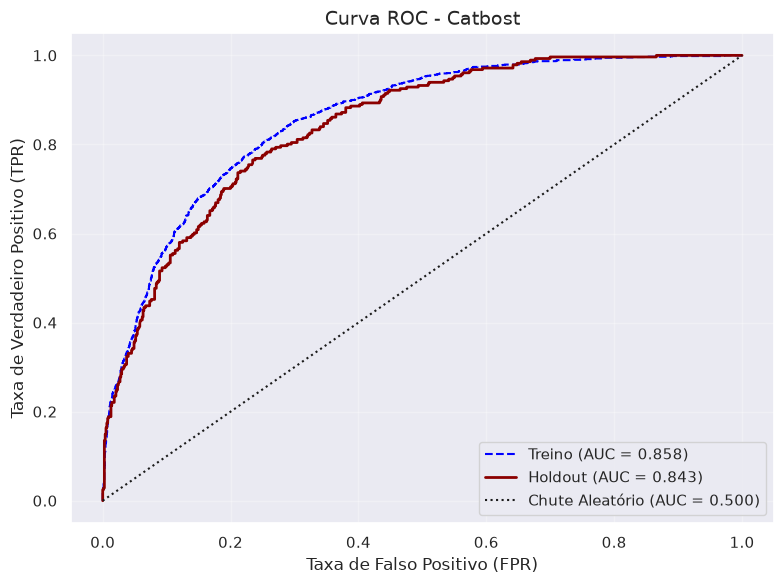

In [174]:
avaliacao.plotar_curva_roc()

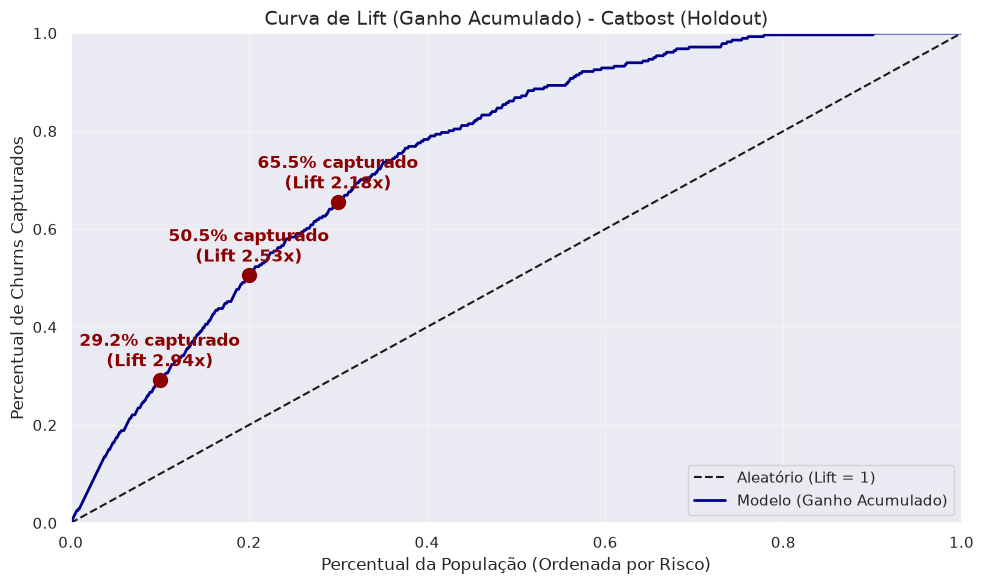

In [175]:
avaliacao.plotar_curva_lift()

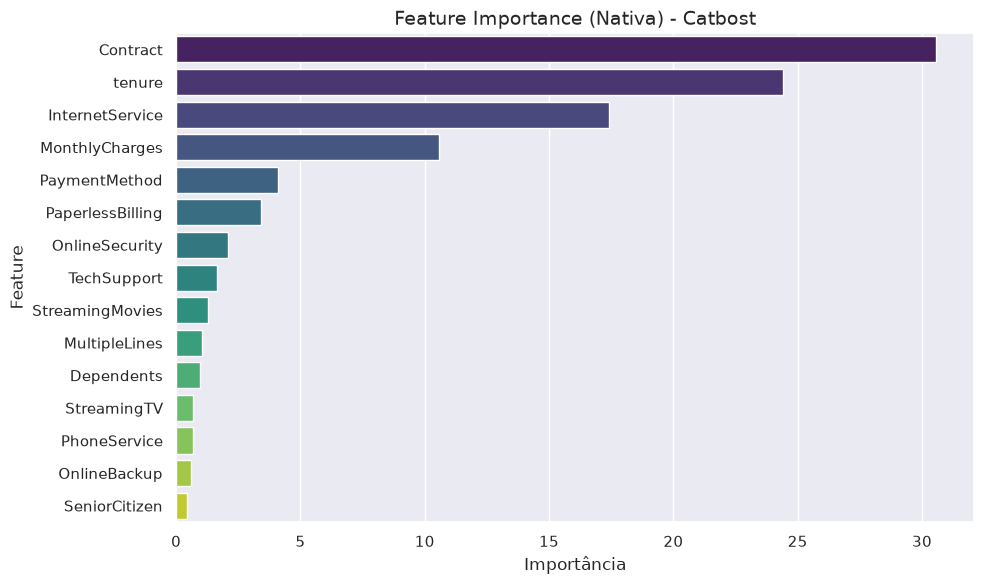

In [176]:
avaliacao.plotar_feature_importance()

In [177]:
pd.DataFrame(
    {
        'Colunas':X_train.columns,
        'Valor': model.feature_importances_
    }
).sort_values(by='Valor', ascending=False)

,Colunas,Valor
14,Contract,30.562719
4,tenure,24.394797
7,InternetService,17.415437
17,MonthlyCharges,10.582939
16,PaymentMethod,4.097300
15,PaperlessBilling,3.400859
8,OnlineSecurity,2.070387
11,TechSupport,1.628597
13,StreamingMovies,1.283904
6,MultipleLines,1.057392
